# Johns Hopkins COVID-19 Analysis and Case Prediction

**Project ID:** PRCP-1023 | **Domain:** Healthcare

**Tasks:** Data Analysis Report, Case Forecasting Model, Recommendations for the Health Department, Model Comparison Report, Challenges Report

## Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')

## Data Understanding

In [2]:
# Data folder and the time series folder inside it
path = r"C:\Johns Hopkins COVID-19\data"
ts_path = path + r"\csse_covid_19_data\csse_covid_19_time_series"

print(os.listdir(ts_path))

['.gitignore', 'Errata.csv', 'README.md', 'time_series_covid19_confirmed_global.csv', 'time_series_covid19_confirmed_US.csv', 'time_series_covid19_deaths_global.csv', 'time_series_covid19_deaths_US.csv', 'time_series_covid19_recovered_global.csv']


## Load the data

In [3]:
# Global cumulative confirmed cases and deaths
cases = pd.read_csv(ts_path + r"\time_series_covid19_confirmed_global.csv")
deaths = pd.read_csv(ts_path + r"\time_series_covid19_deaths_global.csv")

### Data Description

- Source: Johns Hopkins University CSSE COVID-19 data repository
- Files used: global time series of confirmed cases and deaths
- Each row is a country or region. The first four columns are Province/State, Country/Region, Lat and Long
- The remaining columns hold one date each, from 1/22/20 to 3/9/23
- Values are cumulative totals, not daily numbers

In [4]:
# Check the size and the first rows
print(cases.shape, deaths.shape)
cases.head()

(289, 1147) (289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


In [5]:
# Date range covered by the data
print(cases.columns[4], "to", cases.columns[-1])

# Missing values in the date columns
print(cases.iloc[:, 4:].isnull().sum().sum())
print(deaths.iloc[:, 4:].isnull().sum().sum())

1/22/20 to 3/9/23
0
0


In [6]:
# Number of countries and a few examples
print(cases["Country/Region"].nunique())
cases["Country/Region"].unique()[:10]

201


<ArrowStringArray>
[        'Afghanistan',             'Albania',             'Algeria',
             'Andorra',              'Angola',          'Antarctica',
 'Antigua and Barbuda',           'Argentina',             'Armenia',
           'Australia']
Length: 10, dtype: str

### Observations

- Both files have 289 rows and 1147 columns
- The data covers 1/22/20 to 3/9/23
- Province/State has missing values because it applies only to countries that report by region
- Missing values in the date columns: 0 in both the confirmed cases and deaths files
- Number of countries: 201 (289 rows, because some countries are split into several provinces)
- Cumulative values must be converted to daily values before analysis and forecasting

# Data Cleaning and Preparation

## Extract India and build a time series

In [7]:
# Take the India row and turn the date columns into a datetime index
def get_country(data, name):
    row = data[data["Country/Region"] == name].iloc[0, 4:]
    row.index = pd.to_datetime(row.index, format="%m/%d/%y")
    return row.astype(int)

india = pd.DataFrame({"total_cases": get_country(cases, "India"),
                      "total_deaths": get_country(deaths, "India")})
india.head()

,total_cases,total_deaths
2020-01-22,0,0
2020-01-23,0,0
2020-01-24,0,0
2020-01-25,0,0
2020-01-26,0,0


In [8]:
# First date with a case and a death
print(india[india["total_cases"] > 0].index[0])
print(india[india["total_deaths"] > 0].index[0])

2020-01-30 00:00:00
2020-03-11 00:00:00


### Convert cumulative totals to daily numbers

In [9]:
# Daily values are the difference between consecutive days
india["daily_cases"] = india["total_cases"].diff().fillna(0)
india["daily_deaths"] = india["total_deaths"].diff().fillna(0)

# Negative values come from data corrections
print((india[["daily_cases", "daily_deaths"]] < 0).sum())
india.describe()

daily_cases     4
daily_deaths    1
dtype: int64


,total_cases,total_deaths,daily_cases,daily_deaths
count,1.143000e+03,1143.000000,1143.000000,1143.000000
mean,2.548654e+07,319266.174103,39099.508311,464.373578
std,1.759640e+07,209966.402406,71632.400991,820.024588
min,0.000000e+00,0.000000,-1225.000000,-1.000000
25%,8.290750e+06,123354.000000,2063.500000,20.000000
50%,3.222551e+07,431642.000000,13615.000000,179.000000
75%,4.315163e+07,524579.000000,41898.000000,512.500000
max,4.469074e+07,530779.000000,414188.000000,7374.000000


### Handling Negative Values

In [10]:
# Dates with negative daily values
india[(india["daily_cases"] < 0) | (india["daily_deaths"] < 0)]

,total_cases,total_deaths,daily_cases,daily_deaths
2020-03-21,330,4,86.0,-1.0
2022-10-11,44616235,528835,-159.0,13.0
2022-11-07,44660293,530509,-1211.0,0.0
2022-11-17,44667967,530553,-568.0,7.0
2023-02-10,44683862,530750,-1225.0,0.0


In [11]:
# Dates of the 5 highest daily deaths, to check for backlog spikes
india["daily_deaths"].nlargest(5)

2021-06-10    7374.0
2021-05-18    4529.0
2021-05-23    4454.0
2021-05-17    4329.0
2021-05-20    4209.0
Name: daily_deaths, dtype: float64

In [12]:
# Negative values are corrections, so they are set to 0
india["daily_cases"] = india["daily_cases"].clip(lower=0)
india["daily_deaths"] = india["daily_deaths"].clip(lower=0)

print((india[["daily_cases", "daily_deaths"]] < 0).sum())

daily_cases     0
daily_deaths    0
dtype: int64


### 7-Day Smoothing

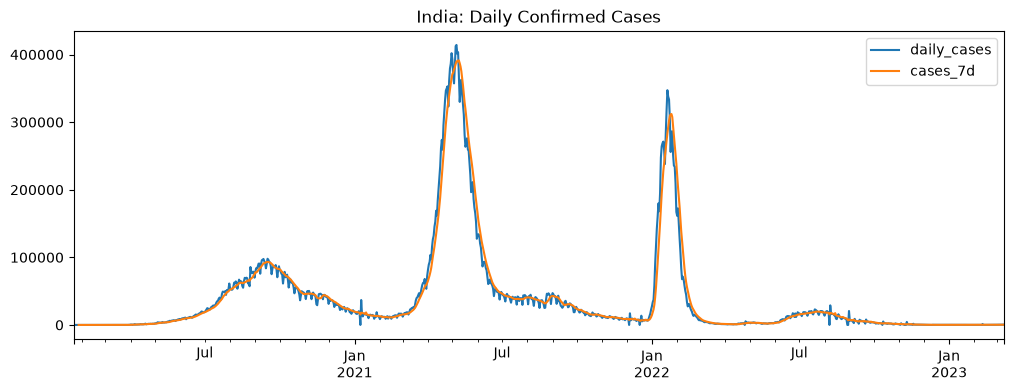

In [13]:
# 7-day rolling average smooths weekly reporting patterns
india["cases_7d"] = india["daily_cases"].rolling(7).mean()
india["deaths_7d"] = india["daily_deaths"].rolling(7).mean()

india[["daily_cases", "cases_7d"]].plot(figsize=(12, 4))
plt.title("India: Daily Confirmed Cases")
plt.show()

### Observations

- India has 1143 days of data, from 2020-01-22 to 2023-03-09
- The original data is cumulative, so daily values were calculated using the difference between consecutive days
- The first days show 0 because India's first confirmed case was reported at the end of January 2020
- 4 negative values in daily cases and 1 in daily deaths were found. They come from downward corrections in the source data, so they were set to 0
- Daily values are noisy because of weekly reporting patterns, so a 7-day rolling average is used to see the trend
- India had three main waves: around Sep 2020, May 2021 (Delta, highest peak) and Jan 2022 (Omicron). After mid-2022, daily cases stay very low
- The highest daily deaths are all in May and June 2021. The value of 7,374 on 2021-06-10 is much higher than the rest, which points to a reporting backlog
- Large peaks are kept because they reflect real waves or reporting backlogs

## Data Analysis

### Global Trend

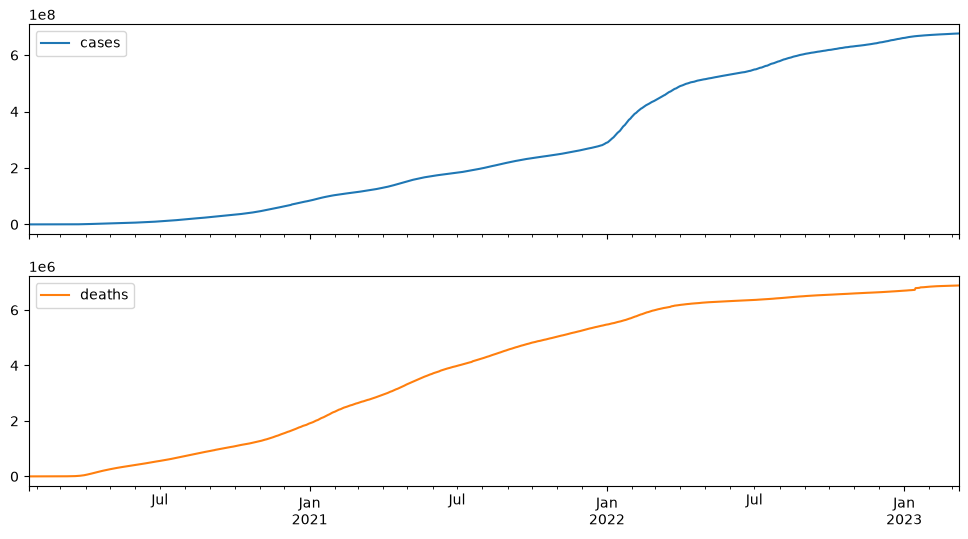

In [14]:
# Total cumulative cases and deaths worldwide per date
world = pd.DataFrame({"cases": cases.iloc[:, 4:].sum(),
                      "deaths": deaths.iloc[:, 4:].sum()})
world.index = pd.to_datetime(world.index, format="%m/%d/%y")

world.plot(subplots=True, figsize=(12, 6))
plt.show()

### Top 10 Countries

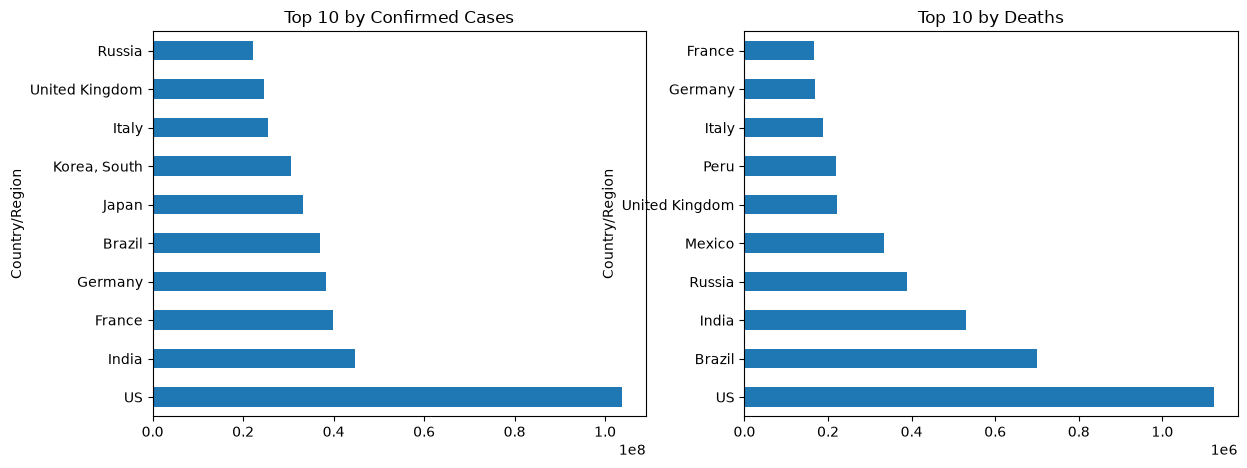

In [15]:
# Latest cumulative totals by country
last = cases.columns[-1]
top_cases = cases.groupby("Country/Region")[last].sum().nlargest(10)
top_deaths = deaths.groupby("Country/Region")[last].sum().nlargest(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_cases.plot(kind="barh", ax=ax[0], title="Top 10 by Confirmed Cases")
top_deaths.plot(kind="barh", ax=ax[1], title="Top 10 by Deaths")
plt.show()

### Case Fatality Rate

In [16]:
# Deaths as a percentage of confirmed cases for the top 10 countries
cfr = (top_cases.index.map(lambda c: deaths.groupby("Country/Region")[last].sum()[c])
       / top_cases.values * 100)
pd.Series(cfr.values, index=top_cases.index).round(2)

Country/Region
US                1.08
India             1.19
France            0.42
Germany           0.44
Brazil            1.89
Japan             0.22
Korea, South      0.11
Italy             0.74
United Kingdom    0.90
Russia            1.76
dtype: float64

### Country Comparison

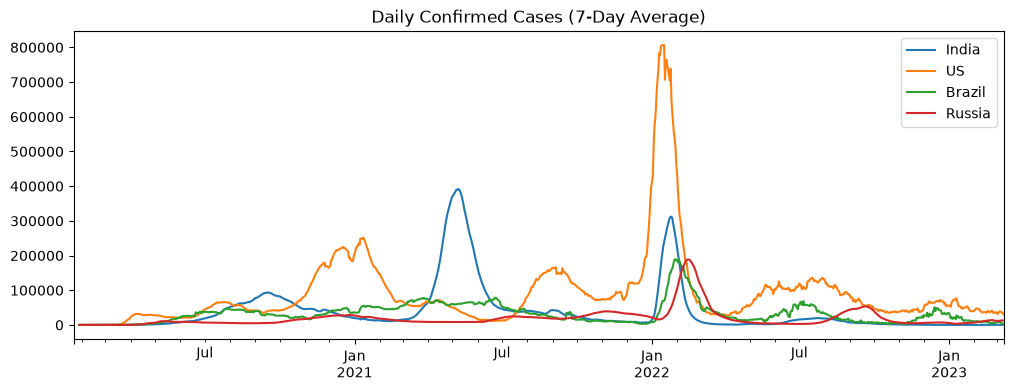

In [17]:
# Daily cases (7-day average) for a country
def daily(data, name):
    row = data[data["Country/Region"] == name].iloc[:, 4:].sum()
    row.index = pd.to_datetime(row.index, format="%m/%d/%y")
    return row.diff().clip(lower=0).rolling(7).mean()

countries = ["India", "US", "Brazil", "Russia"]
compare = pd.DataFrame({c: daily(cases, c) for c in countries})

compare.plot(figsize=(12, 4))
plt.title("Daily Confirmed Cases (7-Day Average)")
plt.show()

### Monthly Cases in India

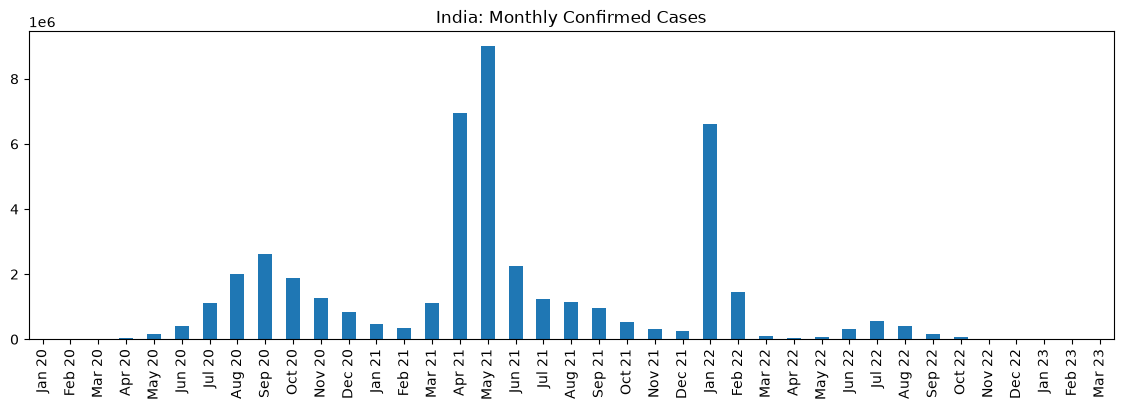

In [18]:
# Total new cases per month with short month-year labels
monthly = india["daily_cases"].resample("ME").sum()
monthly.index = monthly.index.strftime("%b %y")

monthly.plot(kind="bar", figsize=(14, 4))
plt.title("India: Monthly Confirmed Cases")
plt.show()

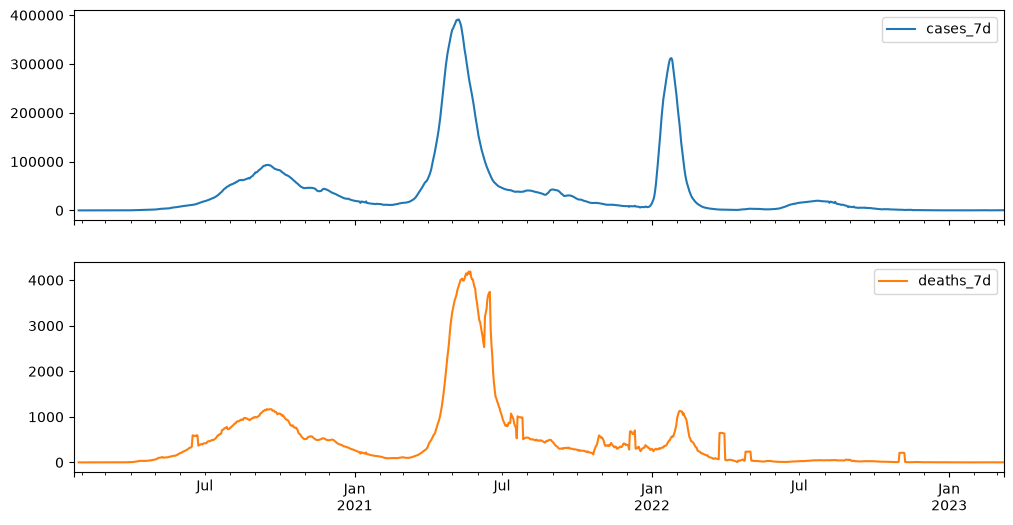

In [19]:
# Daily cases and deaths (7-day average) on the same plot
india[["cases_7d", "deaths_7d"]].plot(subplots=True, figsize=(12, 6))
plt.show()

### Observations

- Worldwide, cases reached about 680 million and deaths about 6.9 million by March 2023
- The US has the most cases and deaths. India is second in cases and third in deaths
- Among the top 10 countries, case fatality rate is highest in Brazil (1.89%) and lowest in South Korea (0.11%). It depends on testing, so it is not a perfect measure
- Most countries peaked together in January 2022 (Omicron)
- India's worst month was May 2021 (Delta), with about 9 million cases
- Deaths follow cases with a delay, and Delta was far deadlier than Omicron in India

## Forecast Setup

### India, daily cases, 30-day forecast.

In [20]:
# Keep data from the first confirmed case, target is daily cases
data = india[india["total_cases"] > 0][["daily_cases"]]
print(data.shape)
data.head()

(1135, 1)


,daily_cases
2020-01-30,1.0
2020-01-31,0.0
2020-02-01,0.0
2020-02-02,1.0
2020-02-03,1.0


### Train and Test Split

(733, 1) (30, 1)


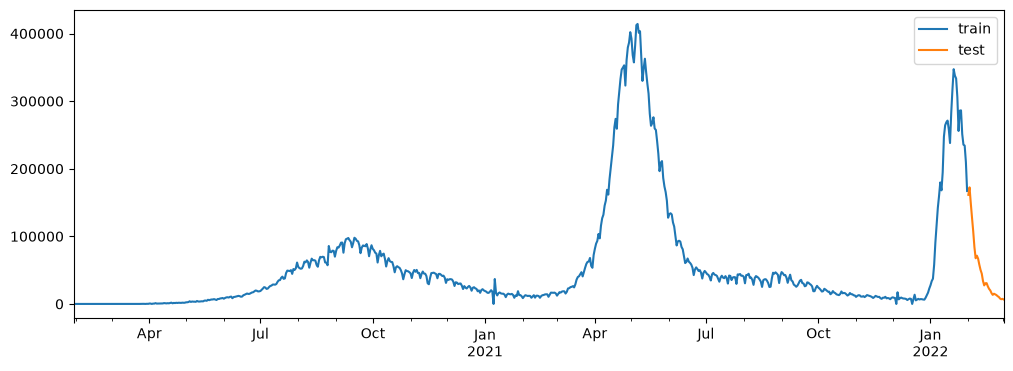

In [21]:
# Training data up to Jan 2022, test data is the next 30 days
train = data[:"2022-01-31"]
test = data["2022-02-01":"2022-03-02"]
print(train.shape, test.shape)

train["daily_cases"].plot(figsize=(12, 4), label="train")
test["daily_cases"].plot(label="test")
plt.legend()
plt.show()

### Baseline Models

In [22]:
# Naive: repeat the last training value
naive = [train["daily_cases"].iloc[-1]] * len(test)

# Moving average: repeat the mean of the last 7 training days
ma = [train["daily_cases"].iloc[-7:].mean()] * len(test)

# MAE and RMSE for both baselines
for name, pred in [("Naive", naive), ("Moving average", ma)]:
    mae = mean_absolute_error(test["daily_cases"], pred)
    rmse = np.sqrt(mean_squared_error(test["daily_cases"], pred))
    print(name, "MAE:", round(mae), "RMSE:", round(rmse))

Naive MAE: 118229 RMSE: 127307
Moving average MAE: 189425 RMSE: 195437


# Modeling

### Scoring Function

In [23]:
# Return MAE and RMSE for a forecast
def score(pred):
    mae = mean_absolute_error(test["daily_cases"], pred)
    rmse = np.sqrt(mean_squared_error(test["daily_cases"], pred))
    return round(mae), round(rmse)

results = {"Naive": score(naive), "Moving average": score(ma)}

### ARIMA

In [24]:
# Fit on training data and forecast the next 30 days
arima_model = ARIMA(train["daily_cases"], order=(7, 1, 1)).fit()
arima = arima_model.forecast(30).clip(lower=0)

results["ARIMA"] = score(arima)

### Random Forest

In [25]:
# Lag features: cases of the previous 7 days
df = data.copy()
for i in range(1, 8):
    df[f"lag{i}"] = df["daily_cases"].shift(i)
df = df.dropna()

train_df = df[:"2022-01-31"]
X_train = train_df.drop(columns="daily_cases")
y_train = train_df["daily_cases"]

rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)

In [26]:
# Forecast 30 days, each prediction becomes the next day's lag
history = list(train["daily_cases"].iloc[-7:])
rf_pred = []

for _ in range(30):
    x = pd.DataFrame([history[::-1]], columns=X_train.columns)
    p = rf.predict(x)[0]
    rf_pred.append(p)
    history = history[1:] + [p]

results["Random Forest"] = score(rf_pred)

### Results

                   MAE    RMSE
Naive           118229  127307
Moving average  189425  195437
ARIMA            15368   17788
Random Forest   124551  133788


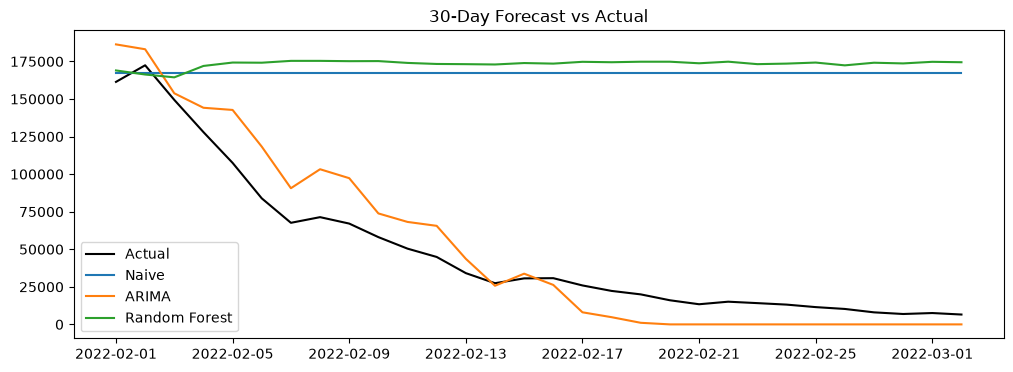

In [27]:
# Scores of all models
print(pd.DataFrame(results, index=["MAE", "RMSE"]).T)

# Forecasts against actual cases
plt.figure(figsize=(12, 4))
plt.plot(test.index, test["daily_cases"], label="Actual", color="black")
plt.plot(test.index, naive, label="Naive")
plt.plot(test.index, arima, label="ARIMA")
plt.plot(test.index, rf_pred, label="Random Forest")
plt.legend()
plt.title("30-Day Forecast vs Actual")
plt.show()

# Model Comparison

                   MAE    RMSE
ARIMA            15368   17788
Naive           118229  127307
Random Forest   124551  133788
Moving average  189425  195437


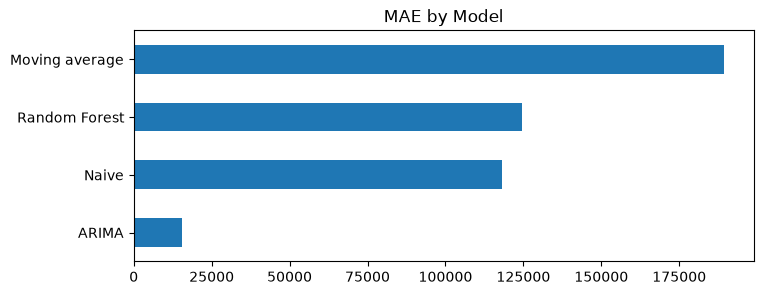

In [28]:
# Sort the models by MAE, lower is better
comparison = pd.DataFrame(results, index=["MAE", "RMSE"]).T.sort_values("MAE")
print(comparison)

comparison["MAE"].plot(kind="barh", figsize=(8, 3), title="MAE by Model")
plt.show()

### Observations

- ARIMA is the best model, with MAE 15,368 and RMSE 17,788, about 8 times better than the naive baseline
- Random Forest is worse than the naive baseline, because tree models cannot predict values outside the range they saw in training, so it stays near the peak level
- ARIMA captures the downward trend, but it overshoots in the first week and underestimates the low values at the end
- Recommended model for production: ARIMA, retrained regularly on the latest data

# Final Forecast

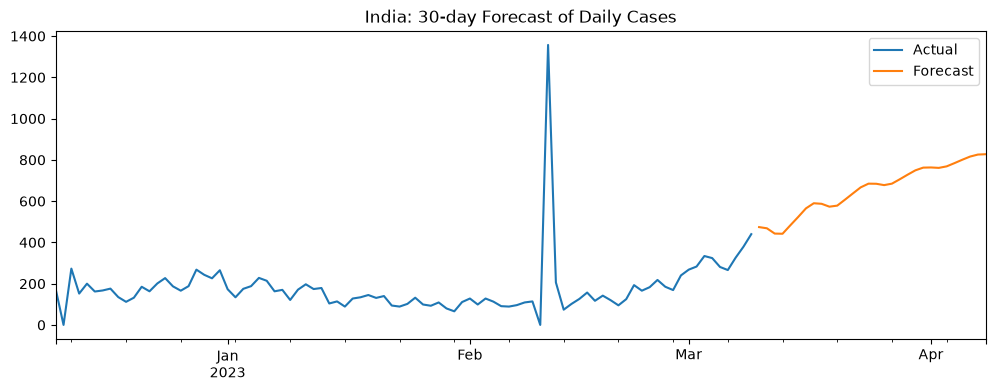

count     30.000000
mean     655.392321
std      121.378769
min      441.906846
25%      574.426974
50%      680.901234
75%      762.090656
max      827.391625
Name: predicted_mean, dtype: float64

In [29]:
# Retrain ARIMA on all data and forecast the next 30 days
final_model = ARIMA(data["daily_cases"], order=(7, 1, 1)).fit()
future = final_model.forecast(30).clip(lower=0)

data["daily_cases"].iloc[-90:].plot(figsize=(12, 4), label="Actual")
future.plot(label="Forecast")
plt.legend()
plt.title("India: 30-day Forecast of Daily Cases")
plt.show()

future.describe()

### Suggestions to the Health Department

- Keep testing and surveillance going, since cases are forecast to rise
- Track the 7-day average every week and retrain the model with fresh data
- Fix trigger levels in advance for extra testing and hospital readiness
- Keep beds, oxygen and medicine stock ready, as the 2021 Delta wave showed
- Continue vaccination and booster drives for high-risk groups
- Improve daily reporting, because delayed batches make forecasts less reliable

### Observations

- The forecast for the next 30 days shows daily cases rising from about 440 to about 830, with an average of about 655
- The rise follows the upward trend already visible in March 2023, but the numbers stay very small compared with earlier waves
- A single-day spike of about 1,360 cases in February 2023 follows a day with 0 cases, which points to a reporting issue

# Challenges Report

| Challenge | Technique used | Reason |
|---|---|---|
| Data was cumulative, not daily | Used `diff()` between consecutive days | Daily cases are needed for analysis and forecasting |
| Negative daily values (4 in cases, 1 in deaths) | Set to 0 with `clip` | They come from downward corrections in the source data |
| Zeros at the start | Started the model data from the first confirmed case (30 Jan 2020) | Early flat days carry no pattern |
| Noisy daily values from weekly reporting | 7-day rolling average | Shows the real trend |
| Reporting backlogs (deaths spike on 10 Jun 2021, case spike in Feb 2023) | Kept the values | They are real reports, and removing them would hide information |
| Test period close to zero would make a model look good | Chose a 30-day test window after the Omicron peak | A window with real movement gives a fairer comparison |
| Random Forest failed on a falling trend | Compared it with simple baselines and ARIMA | Tree models cannot predict values outside the range seen in training |
| Percentage errors break near zero cases | Used MAE and RMSE | They work with values close to zero |
| Only one test window | Noted as a limitation | Results may change in a rising phase |